# 01 · Preprocessing — Caron et al. 2020 (Pediatric B/T-ALL, 10x)
Load malignant cells, threshold under-populated samples, select overdispersed genes, PCA, Harmony on `sample`, UMAP. **Gate 1** (01->02): is the malignant manifold both *sample-mixed* and *continuous*? Caron pools three genetically distinct ALL groups (ETV6-RUNX1 Pre-B, high-hyperdiploid B-ALL, Pre-T) across 8 patients - the integration is the crux. Judged on the regenerated embedding plus a per-neighbourhood mixing metric (iLISI), not a scalar alone.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Caron2020_Hematologic | category: Hematologic


### Load malignant cells
Loader auto-detects UMI counts -> `normalize_total` -> `log1p`. Select the publication's `Malignant` annotation.

In [ ]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())
print('ALL subtype (source) composition:', adata.obs['source'].value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Caron2020_Hematologic
Done.
full atlas: (37320, 33694)
malignant: (25788, 33694) | samples: 8
expression: X max 7.17 (log1p of normalize_total UMI counts)
ALL subtype (source) composition: {'Pre-B_ALL': 13017, 'Pre-B_High_hyper_diploid_ALL': 7926, 'Pre-T_ALL': 4845}


/home/caleb/miniconda3/envs/scFates/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


### Sample threshold — gap-finding (derived, not inherited)
Sort per-sample malignant counts; look for a dominant spillover cliff. If none, keep the floor (>=100). Caron's 8 malignant samples are all well-populated (min 1585), so the floor applies and all are kept.

In [ ]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]
top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no dominant cliff (all malignant samples well-populated) -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'ETV6.RUNX1.2': np.int64(5816), 'HHD.2': np.int64(4780), 'HHD.1': np.int64(3146), 'ETV6.RUNX1.4': np.int64(3022), 'PRE-T.1': np.int64(2866), 'ETV6.RUNX1.1': np.int64(2594), 'PRE-T.2': np.int64(1979), 'ETV6.RUNX1.3': np.int64(1585)}
gap ratios: ['5816->4780:1.22', '4780->3146:1.52', '3146->3022:1.04', '3022->2866:1.05', '2866->2594:1.10', '2594->1979:1.31', '1979->1585:1.25']
argmax gap 4780->3146 (ratio 1.52); top/second = 1.16; dominant cliff = False
no dominant cliff (all malignant samples well-populated) -> floor >= 100
kept 8/8 samples (min per-sample = 1585) -> 25788 cells


### Genes -> overdispersion -> PCA -> Harmony integration sweep
Harmony `theta` swept 2/5/10; mixing read as the mean same-sample fraction among 30 nearest neighbours (lower = better mixed). Pre-Harmony the manifold is almost perfectly patient-segregated; integration must be strong to merge three genetic ALL groups without collapsing biology.

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base, '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta,
      '(mixing improves sharply to theta=5 then flattens; strongest integration chosen for the strong',
      'patient/subtype batch structure, without collapsing continuity)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1332 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1332
same-sample neighbour fraction | pre-Harmony 0.999 | sweep {2: 0.407, 5: 0.272, 10: 0.272}
selected theta = 10 (mixing improves sharply to theta=5 then flattens; strongest integration chosen for the strong patient/subtype batch structure, without collapsing continuity)


2026-08-04 19:05:55,211 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 19:05:57,834 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 19:05:58,000 - harmonypy - INFO - Iteration 1 of 30
2026-08-04 19:06:07,333 - harmonypy - INFO - Iteration 2 of 30
2026-08-04 19:06:15,959 - harmonypy - INFO - Converged after 2 iterations
2026-08-04 19:06:17,233 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 19:06:19,790 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 19:06:19,958 - harmonypy - INFO - Iteration 1 of 30
2026-08-04 19:06:28,361 - harmonypy - INFO - Iteration 2 of 30
2026-08-04 19:06:38,073 - harmonypy - INFO - Iteration 3 of 30
2026-08-04 19:06:48,156 - harmonypy - INFO - Iteration 4 of 30
2026-08-04 19:06:57,491 - harmonypy - INFO - Iteration 5 of 30
2026-08-04 19:07:04,040 - harmonypy - INFO - Iteration 6 of 30
2026-08-04 19:07:11,234 - harmonypy - INFO - Iteration 7 of 

### Island removal — connected components on a UMAP radius graph
Radius graph at 6x the median nearest-neighbour distance; keep the largest connected component. Strictly conservative - strips only disconnected specks.

In [ ]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('connected components:', ncomp, '| removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0], 'cells')

connected components: 1 | removed 0 cells in 0 detached islands
after island removal: 25788 cells


### Sub-region identity — biology before geometry
Leiden lobes at low resolution; is any split a real lineage divide or just cell cycle? B markers (CD19/CD79A/VPREB1/DNTT) vs T markers (CD3D/CD3E/CD7) and a proliferation score decide. Caron's manifold resolves into a large resting body and a small cycling cap with near-identical lineage identity -> the split is proliferation, not B-vs-T. One low-cycling body carries the trajectory.

In [ ]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
print('lobe x ALL subtype:'); print(pd.crosstab(adata.obs['lobe'], adata.obs['source']))
mk_b = [g for g in ['CD19','CD79A','VPREB1','DNTT'] if g in adata.var_names]
mk_t = [g for g in ['CD3D','CD3E','CD7'] if g in adata.var_names]
sc.tl.score_genes(adata, mk_b, score_name='B_score', random_state=SEED)
sc.tl.score_genes(adata, mk_t, score_name='T_score', random_state=SEED)
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('B-lineage score per lobe:', adata.obs.groupby('lobe', observed=True)['B_score'].mean().round(3).to_dict())
print('T-lineage score per lobe:', adata.obs.groupby('lobe', observed=True)['T_score'].mean().round(3).to_dict())
print('proliferation score per lobe:', adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
adata.obs['compartment'] = 'Body'
adata.obs['compartment'] = adata.obs['compartment'].astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'1': 19815, '0': 5973}
cycling fraction per lobe: {'0': 0.865, '1': 0.06}
lobe x ALL subtype:
source  Pre-B_ALL  Pre-B_High_hyper_diploid_ALL  Pre-T_ALL
lobe                                                      
0            2927                          1782       1264
1           10090                          6144       3581
B-lineage score per lobe: {'0': 0.278, '1': 0.358}
T-lineage score per lobe: {'0': -0.23, '1': -0.182}
proliferation score per lobe: {'0': 0.519, '1': -0.053}
compartments: {'Body': 25788}


### House orientation — rigid rotation to a horizontal strip
Store a distance-preserving rotation (`X_umap_lin`) with the Gast/pSom-high developmental origin on the left, so every downstream panel shares one orientation. Origin pole derived from graph-smoothed module scores.

In [ ]:
import scipy.sparse as sp
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = (S[:,0] + S[:,1]) - S[:,2]

xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), Gast/pSom-high origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.38
house orientation: rigid rotation -151.6deg (distances preserved), Gast/pSom-high origin pole on left; stored as X_umap_lin


### Gate 1 — mixing + continuity (per-neighbourhood iLISI)
iLISI = effective number of samples among each cell's 90 nearest neighbours (1 = segregated, 8 = fully mixed).

In [ ]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} patients (3 ALL genetic groups) share one continuous manifold (one connected component, no islands removed).')
print('Gate 1: samples + subtypes intermix per-neighbourhood on one continuous manifold -> GO')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 4.71 of 8 samples
8 patients (3 ALL genetic groups) share one continuous manifold (one connected component, no islands removed).
Gate 1: samples + subtypes intermix per-neighbourhood on one continuous manifold -> GO


### Save processed data

In [ ]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','disease','patient'}
for c in adata.obs.columns:
    if c in protect:
        adata.obs[c] = adata.obs[c].astype(str).astype('category'); continue
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (25788, 21935)


### `samples.pdf` — sample-coloured manifold (Gate-1 integration evidence)
House `(3.5,1.5)` strip on the shared orientation; intermixing across the strip is the batch-integration readout.

saved samples.pdf | cells: 25788


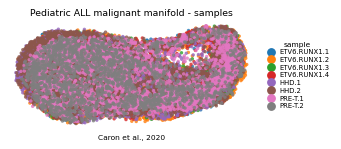

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Pediatric ALL malignant manifold - samples', size=7.5)
ax.text(.5, -.12, 'Caron et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])